# Evaluating Faithfulness and Robustness of Grad-CAM Explanations in Vision Transformers

## Project Overview

This research evaluates the faithfulness and robustness of Grad-CAM explanations generated for three vision transformer-based image classification models: Partial ViT, Deep-head ViT, and Swin Transformer.

The study uses the Indian Medicinal Leaves Image Dataset and investigates how effectively Grad-CAM explanations represent model behaviour and how consistently these explanations respond to input image transformations.

The evaluation focuses on two major aspects:

1. **Faithfulness:** Evaluated using deletion and insertion tests.
2. **Robustness:** Evaluated using brightness adjustment, Gaussian blur, and Gaussian noise transformations.

Classification performance, explanation similarity, and prediction consistency are analyzed to compare the behaviour of the three models.

## 1. Environment and Dataset Preparation

In [1]:
# ==========================================
# 1. ENVIRONMENT AND DATASET SETUP
# ==========================================

import os
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Model directory
MODEL_DIR = (
    "/kaggle/input/datasets/panchabaviharshini/"
    "experiment-results"
)

# Dataset directory
DATASET_DIR = (
    "/kaggle/input/datasets/aryashah2k/"
    "indian-medicinal-leaves-dataset"
)

DATASET_PATH = os.path.join(
    DATASET_DIR,
    "Indian Medicinal Leaves Image Datasets",
    "Medicinal Leaf dataset"
)

VIT_DIR = os.path.join(
    MODEL_DIR,
    "ViT_Experiments_2_and_3"
)

SWIN_DIR = os.path.join(
    MODEL_DIR,
    "Swin_Transformer_Experiment_4"
)

print("Device:", device)
print("CUDA available:", torch.cuda.is_available())
print("Dataset exists:", os.path.exists(DATASET_PATH))
print("ViT checkpoints exist:", os.path.exists(VIT_DIR))
print("Swin checkpoint exists:", os.path.exists(SWIN_DIR))

Device: cpu
CUDA available: False
Dataset exists: True
ViT checkpoints exist: True
Swin checkpoint exists: True


In [2]:
# ==========================================
# 2. DATASET PREPARATION
# ==========================================

image_paths = []
image_labels = []

# Collect image paths and their class labels
for class_name in os.listdir(DATASET_PATH):

    class_path = os.path.join(DATASET_PATH, class_name)

    if os.path.isdir(class_path):

        for file in os.listdir(class_path):

            if file.lower().endswith(
                (".jpg", ".jpeg", ".png")
            ):
                image_paths.append(
                    os.path.join(class_path, file)
                )

                image_labels.append(class_name)

# Encode class labels
label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(image_labels)

class_names = label_encoder.classes_.tolist()

print("Total images:", len(image_paths))
print("Total classes:", len(class_names))

# Original 80:20 train and temporary split
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    encoded_labels,
    test_size=0.20,
    random_state=42,
    stratify=encoded_labels
)

# Split remaining data equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nDataset split:")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

# Save split manifest
split_df = pd.DataFrame({
    "image_path": X_train + X_val + X_test,
    "label": np.concatenate([
        y_train, y_val, y_test
    ]),
    "split": (
        ["train"] * len(X_train)
        + ["validation"] * len(X_val)
        + ["test"] * len(X_test)
    )
})

split_df.to_csv(
    "/kaggle/working/dataset_split_manifest.csv",
    index=False
)

print("\nDataset split manifest saved.")

Total images: 6900
Total classes: 80

Dataset split:
Training: 5520
Validation: 690
Testing: 690

Dataset split manifest saved.


In [3]:
# ==========================================
# 3. IMAGE PREPROCESSING AND DATALOADERS
# ==========================================

from transformers import AutoImageProcessor

# Load preprocessing configurations
vit_processor = AutoImageProcessor.from_pretrained(
    "google/vit-base-patch16-224-in21k"
)

swin_processor = AutoImageProcessor.from_pretrained(
    SWIN_DIR,
    local_files_only=True
)


# Custom Dataset
class LeafDataset(Dataset):

    def __init__(self, image_paths, labels, processor):
        self.image_paths = image_paths
        self.labels = labels
        self.processor = processor

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        image = Image.open(
            self.image_paths[idx]
        ).convert("RGB")

        pixel_values = self.processor(
            images=image,
            return_tensors="pt"
        )["pixel_values"].squeeze(0)

        label = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return pixel_values, label


# Create separate test datasets for ViT and Swin
vit_test_dataset = LeafDataset(
    X_test, y_test, vit_processor
)

swin_test_dataset = LeafDataset(
    X_test, y_test, swin_processor
)

BATCH_SIZE = 32

vit_test_loader = DataLoader(
    vit_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

swin_test_loader = DataLoader(
    swin_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("ViT test images:", len(vit_test_dataset))
print("Swin test images:", len(swin_test_dataset))

# Check one batch
images, labels = next(iter(vit_test_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

ViT test images: 690
Swin test images: 690
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


## 2. Model Reconstruction and Checkpoint Loading

In [4]:
# ==========================================
# 4. RECONSTRUCT AND LOAD VIT MODELS
# ==========================================

from transformers import ViTConfig, ViTForImageClassification

vit_config = ViTConfig(
    image_size=224,
    patch_size=16,
    num_channels=3,
    hidden_size=768,
    num_hidden_layers=12,
    num_attention_heads=12,
    intermediate_size=3072,
    num_labels=80,
    hidden_dropout_prob=0.0,
    attention_probs_dropout_prob=0.0
)


def convert_vit_keys(state_dict):

    converted = {}

    replacements = {
        "vit.encoder.layer.": "vit.layers.",
        ".attention.attention.query.": ".attention.q_proj.",
        ".attention.attention.key.": ".attention.k_proj.",
        ".attention.attention.value.": ".attention.v_proj.",
        ".attention.output.dense.": ".attention.o_proj.",
        ".intermediate.dense.": ".mlp.fc1.",
        ".output.dense.": ".mlp.fc2."
    }

    for key, value in state_dict.items():

        new_key = key

        for old, new in replacements.items():
            new_key = new_key.replace(old, new)

        converted[new_key] = value

    return converted


def build_vit_model(checkpoint_path):

    state_dict = torch.load(
        checkpoint_path,
        map_location="cpu"
    )

    if "state_dict" in state_dict:
        state_dict = state_dict["state_dict"]

    # Reconstruct the exact classifier architecture
    if "classifier.6.weight" in state_dict:

        model_head = nn.Sequential(
            nn.Linear(768, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 80)
        )

    elif "classifier.3.weight" in state_dict:

        hidden_dim = state_dict["classifier.0.weight"].shape[0]

        model_head = nn.Sequential(
            nn.Linear(768, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, 80)
        )

    else:
        model_head = nn.Linear(768, 80)

    model = ViTForImageClassification(vit_config)
    model.classifier = model_head

    state_dict = convert_vit_keys(state_dict)

    model.load_state_dict(state_dict, strict=True)

    model = model.to(device)
    model.eval()

    return model


# Load partial fine-tuned ViT
vit_partial_model = build_vit_model(
    os.path.join(VIT_DIR, "best_vit_partial_model.pth")
)

# Load deeper-head ViT
vit_deep_model = build_vit_model(
    os.path.join(VIT_DIR, "best_vit_deep_model.pth")
)

print("Both ViT models loaded successfully!")
print("\nPartial ViT classifier:")
print(vit_partial_model.classifier)

print("\nDeep-head ViT classifier:")
print(vit_deep_model.classifier)

Both ViT models loaded successfully!

Partial ViT classifier:
Sequential(
  (0): Linear(in_features=768, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=256, out_features=80, bias=True)
)

Deep-head ViT classifier:
Sequential(
  (0): Linear(in_features=768, out_features=512, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=256, out_features=80, bias=True)
)


In [5]:
# ==========================================
# 5. LOAD SWIN TRANSFORMER
# ==========================================

from transformers import SwinForImageClassification

swin_model = SwinForImageClassification.from_pretrained(
    SWIN_DIR,
    local_files_only=True
)

swin_model = swin_model.to(device)
swin_model.eval()

# Verify number of output classes
print("Swin Transformer loaded successfully!")
print("Number of classes:", swin_model.config.num_labels)

# Verify class names
with open(
    os.path.join(SWIN_DIR, "class_names.json"),
    "r"
) as f:
    swin_class_names = json.load(f)

print("Number of saved class names:", len(swin_class_names))
print("Class names match:", swin_class_names == class_names)

Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

Swin Transformer loaded successfully!
Number of classes: 80
Number of saved class names: 80
Class names match: True


In [22]:
# Verify class-to-index mapping

print("Number of classes:", len(class_names))
print("\nFirst 10 class mappings:")

for idx, name in enumerate(class_names[:10]):
    print(idx, ":", name)

print("\nViT classifier output classes:", 
      vit_partial_model.config.num_labels)

print("Swin classifier output classes:", 
      swin_model.config.num_labels)

Number of classes: 80

First 10 class mappings:
0 : Aloevera
1 : Amla
2 : Amruthaballi
3 : Arali
4 : Astma_weed
5 : Badipala
6 : Balloon_Vine
7 : Bamboo
8 : Beans
9 : Betel

ViT classifier output classes: 80
Swin classifier output classes: 80


In [23]:
print("ViT class mapping matches current dataset:",
      list(label_encoder.classes_) == class_names)

print("First class:", label_encoder.classes_[0])
print("Last class:", label_encoder.classes_[-1])

ViT class mapping matches current dataset: True
First class: Aloevera
Last class: kepala


In [6]:
# ==========================================
# 6. MODEL FORWARD-PASS CHECK
# ==========================================

# Get one batch for each model
vit_images, vit_labels = next(iter(vit_test_loader))
swin_images, swin_labels = next(iter(swin_test_loader))

# Move images to device
vit_images = vit_images.to(device)
swin_images = swin_images.to(device)

# Test predictions
with torch.no_grad():

    partial_outputs = vit_partial_model(
        pixel_values=vit_images
    ).logits

    deep_outputs = vit_deep_model(
        pixel_values=vit_images
    ).logits

    swin_outputs = swin_model(
        pixel_values=swin_images
    ).logits


print("Partial ViT output shape:", partial_outputs.shape)
print("Deep ViT output shape:", deep_outputs.shape)
print("Swin output shape:", swin_outputs.shape)

# Check predicted classes
print("\nSample predictions:")
print("Partial ViT:", partial_outputs.argmax(dim=1)[:5].cpu().numpy())
print("Deep ViT:", deep_outputs.argmax(dim=1)[:5].cpu().numpy())
print("Swin:", swin_outputs.argmax(dim=1)[:5].cpu().numpy())
print("Actual labels:", vit_labels[:5].numpy())

Partial ViT output shape: torch.Size([32, 80])
Deep ViT output shape: torch.Size([32, 80])
Swin output shape: torch.Size([32, 80])

Sample predictions:
Partial ViT: [58 18 56 45 20]
Deep ViT: [58 64 56 45 20]
Swin: [58 18 56 45 20]
Actual labels: [58 18 56 45 20]


## 3. Model Performance Evaluation

In [7]:
# ==========================================
# 7. EVALUATE ALL THREE MODELS
# ==========================================

def evaluate_model(model, dataloader, model_name):

    all_predictions = []
    all_labels = []

    model.eval()

    with torch.no_grad():

        for images, labels in dataloader:

            images = images.to(device)

            outputs = model(
                pixel_values=images
            ).logits

            predictions = torch.argmax(
                outputs, dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    print(f"\n{model_name} Evaluation Complete")

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }


# Evaluate all models
results = []

results.append(
    evaluate_model(
        vit_partial_model,
        vit_test_loader,
        "Partial ViT"
    )
)

results.append(
    evaluate_model(
        vit_deep_model,
        vit_test_loader,
        "Deep-head ViT"
    )
)

results.append(
    evaluate_model(
        swin_model,
        swin_test_loader,
        "Swin Transformer"
    )
)


# Create comparison table
results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}"
    })
)

# Save results
results_df.to_csv(
    "/kaggle/working/model_comparison.csv",
    index=False
)

print("\nResults saved successfully.")


Partial ViT Evaluation Complete

Deep-head ViT Evaluation Complete

Swin Transformer Evaluation Complete

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Partial ViT,0.9522,0.9345,0.9264,0.9271
1,Deep-head ViT,0.9406,0.9229,0.9214,0.9181
2,Swin Transformer,0.9710,0.9765,0.9729,0.9730



Results saved successfully.


## 4. Grad-CAM Implementation

In [9]:
# ==========================================
# 8. INSPECT VIT LAYERS FOR GRAD-CAM
# ==========================================

print("PARTIAL ViT MODULES")
for name, module in vit_partial_model.named_modules():

    if "layer" in name.lower():
        print(name, ":", type(module).__name__)


print("\nDEEP-HEAD ViT MODULES")
for name, module in vit_deep_model.named_modules():

    if "layer" in name.lower():
        print(name, ":", type(module).__name__)

PARTIAL ViT MODULES
vit.layers : ModuleList
vit.layers.0 : ViTLayer
vit.layers.0.attention : ViTAttention
vit.layers.0.attention.q_proj : Linear
vit.layers.0.attention.k_proj : Linear
vit.layers.0.attention.v_proj : Linear
vit.layers.0.attention.o_proj : Linear
vit.layers.0.layernorm_before : LayerNorm
vit.layers.0.layernorm_after : LayerNorm
vit.layers.0.mlp : ViTMLP
vit.layers.0.mlp.activation_fn : GELUActivation
vit.layers.0.mlp.fc1 : Linear
vit.layers.0.mlp.fc2 : Linear
vit.layers.0.dropout : Dropout
vit.layers.1 : ViTLayer
vit.layers.1.attention : ViTAttention
vit.layers.1.attention.q_proj : Linear
vit.layers.1.attention.k_proj : Linear
vit.layers.1.attention.v_proj : Linear
vit.layers.1.attention.o_proj : Linear
vit.layers.1.layernorm_before : LayerNorm
vit.layers.1.layernorm_after : LayerNorm
vit.layers.1.mlp : ViTMLP
vit.layers.1.mlp.activation_fn : GELUActivation
vit.layers.1.mlp.fc1 : Linear
vit.layers.1.mlp.fc2 : Linear
vit.layers.1.dropout : Dropout
vit.layers.2 : ViTLayer


In [10]:
# ==========================================
# 9. VIT GRAD-CAM IMPLEMENTATION
# ==========================================

class ViTGradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer
        self.activations = None

        self.forward_hook = target_layer.register_forward_hook(
            self.save_activations
        )

    def save_activations(self, module, inputs, output):

        self.activations = output

    def generate(self, image, target_class=None):

        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        # Forward pass
        outputs = self.model(pixel_values=image)
        logits = outputs.logits

        if target_class is None:
            target_class = logits.argmax(dim=1).item()

        # Calculate gradients with respect to target-layer activations
        gradients = torch.autograd.grad(
            outputs=logits[0, target_class],
            inputs=self.activations
        )[0]

        activations = self.activations[:, 1:, :]
        gradients = gradients[:, 1:, :]

        # Gradient weights
        weights = gradients.mean(dim=1, keepdim=True)

        # Grad-CAM calculation
        cam = (weights * activations).sum(dim=2)
        cam = torch.relu(cam)

        # Reshape patch tokens into 14 x 14
        cam = cam.reshape(1, 1, 14, 14)

        # Normalize
        cam_min = cam.min()
        cam_max = cam.max()

        cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)

        return cam.detach(), target_class

    def remove_hooks(self):

        self.forward_hook.remove()


# Initialize Grad-CAM using the penultimate transformer block

partial_gradcam = ViTGradCAM(
    vit_partial_model,
    vit_partial_model.vit.layers[10]
)

deep_gradcam = ViTGradCAM(
    vit_deep_model,
    vit_deep_model.vit.layers[10]
)

print("Grad-CAM initialized using the penultimate ViT block.")

Grad-CAM initialized using the penultimate ViT block.


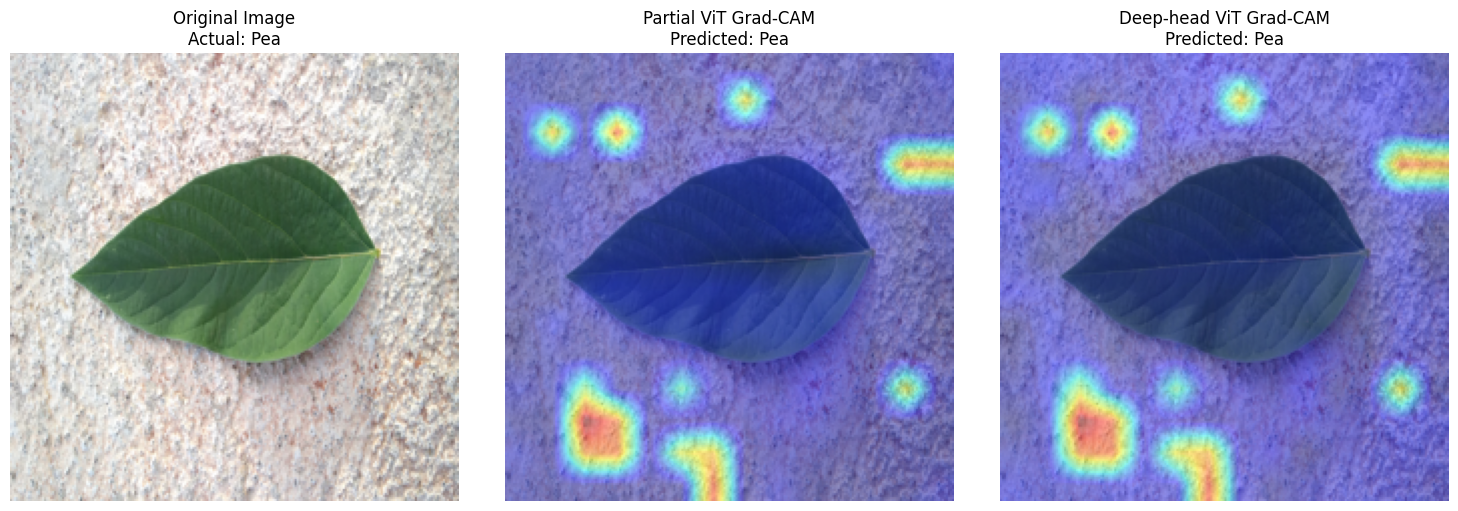

In [11]:
# ==========================================
# 10. GENERATE GRAD-CAM HEATMAPS
# ==========================================

import matplotlib.pyplot as plt
import torch.nn.functional as F

# Select one test image
sample_idx = 0

image_tensor, actual_label = vit_test_dataset[sample_idx]

image_batch = image_tensor.unsqueeze(0).to(device)

# Generate Grad-CAM for both models
partial_cam, partial_pred = partial_gradcam.generate(
    image_batch
)

deep_cam, deep_pred = deep_gradcam.generate(
    image_batch
)

# Resize heatmaps to original image dimensions
partial_cam = F.interpolate(
    partial_cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

deep_cam = F.interpolate(
    deep_cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

# Load the original image without normalization
display_image = Image.open(X_test[sample_idx]).convert("RGB")
display_image = display_image.resize((224, 224))
display_image = np.array(display_image)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(display_image)
axes[0].set_title(
    f"Original Image\nActual: {class_names[actual_label.item()]}"
)

axes[1].imshow(display_image)
axes[1].imshow(
    partial_cam.squeeze().cpu().numpy(),
    cmap="jet",
    alpha=0.45
)
axes[1].set_title(
    f"Partial ViT Grad-CAM\nPredicted: {class_names[partial_pred]}"
)

axes[2].imshow(display_image)
axes[2].imshow(
    deep_cam.squeeze().cpu().numpy(),
    cmap="jet",
    alpha=0.45
)
axes[2].set_title(
    f"Deep-head ViT Grad-CAM\nPredicted: {class_names[deep_pred]}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# ==========================================
# 11. GRAD-CAM HEATMAP COMPARISON
# ==========================================

partial_array = partial_cam.squeeze().cpu().numpy()
deep_array = deep_cam.squeeze().cpu().numpy()

print("Partial ViT:")
print("Minimum:", partial_array.min())
print("Maximum:", partial_array.max())
print("Mean:", partial_array.mean())
print("Standard deviation:", partial_array.std())

print("\nDeep-head ViT:")
print("Minimum:", deep_array.min())
print("Maximum:", deep_array.max())
print("Mean:", deep_array.mean())
print("Standard deviation:", deep_array.std())

print(
    "\nMean absolute difference:",
    np.mean(np.abs(partial_array - deep_array))
)

Partial ViT:
Minimum: 0.00012862863
Maximum: 0.98650324
Mean: 0.09962938
Standard deviation: 0.14132294

Deep-head ViT:
Minimum: 0.00039392177
Maximum: 0.9883349
Mean: 0.10848993
Standard deviation: 0.14980526

Mean absolute difference: 0.042563703


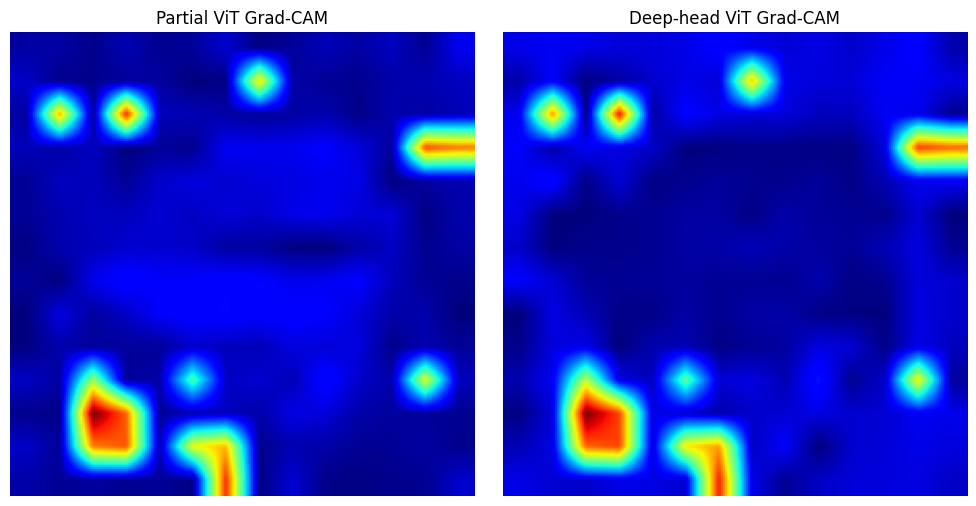

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(partial_array, cmap="jet")
axes[0].set_title("Partial ViT Grad-CAM")
axes[0].axis("off")

axes[1].imshow(deep_array, cmap="jet")
axes[1].set_title("Deep-head ViT Grad-CAM")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [14]:
# ==========================================
# 12. DEBUG GRAD-CAM
# ==========================================

def debug_gradcam(model, image, target_layer):

    activations = []
    gradients = []

    def forward_hook(module, inputs, output):
        activations.append(output.detach())

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0].detach())

    h1 = target_layer.register_forward_hook(forward_hook)
    h2 = target_layer.register_full_backward_hook(backward_hook)

    model.eval()
    model.zero_grad()

    outputs = model(pixel_values=image)
    predicted_class = outputs.logits.argmax(dim=1).item()

    score = outputs.logits[:, predicted_class]
    score.backward()

    h1.remove()
    h2.remove()

    print("Predicted class:", predicted_class)

    print("\nActivation shape:", activations[0].shape)
    print("Activation min:", activations[0].min().item())
    print("Activation max:", activations[0].max().item())

    print("\nGradient shape:", gradients[0].shape)
    print("Gradient min:", gradients[0].min().item())
    print("Gradient max:", gradients[0].max().item())
    print("Gradient mean:", gradients[0].mean().item())
    print("Gradient absolute mean:", gradients[0].abs().mean().item())


print("PARTIAL ViT")
debug_gradcam(
    vit_partial_model,
    image_batch,
    vit_partial_model.vit.layers[11]
)

print("\nDEEP-HEAD ViT")
debug_gradcam(
    vit_deep_model,
    image_batch,
    vit_deep_model.vit.layers[11]
)

PARTIAL ViT
Predicted class: 58

Activation shape: torch.Size([1, 197, 768])
Activation min: -887.1507568359375
Activation max: 1510.2186279296875

Gradient shape: torch.Size([1, 197, 768])
Gradient min: -0.0033145295456051826
Gradient max: 0.0029076216742396355
Gradient mean: -7.232867869086737e-14
Gradient absolute mean: 4.4901039473188575e-06

DEEP-HEAD ViT
Predicted class: 58

Activation shape: torch.Size([1, 197, 768])
Activation min: -905.5361328125
Activation max: 1506.2685546875

Gradient shape: torch.Size([1, 197, 768])
Gradient min: -0.0033346416894346476
Gradient max: 0.003823625622317195
Gradient mean: -6.001741394449575e-14
Gradient absolute mean: 5.09045230501215e-06


In [15]:
# ==========================================
# 12. VERIFY GRAD-CAM AT BLOCK 10
# ==========================================

def inspect_gradcam_calculation(model, image, target_layer):

    captured = {}

    def forward_hook(module, inputs, output):
        captured["activations"] = output

    hook = target_layer.register_forward_hook(forward_hook)

    model.eval()
    model.zero_grad(set_to_none=True)

    outputs = model(pixel_values=image)
    predicted_class = outputs.logits.argmax(dim=1).item()

    activations = captured["activations"]

    gradients = torch.autograd.grad(
        outputs=outputs.logits[0, predicted_class],
        inputs=activations
    )[0]

    hook.remove()

    # Remove CLS token
    A = activations[:, 1:, :]
    G = gradients[:, 1:, :]

    weights = G.mean(dim=1, keepdim=True)
    raw_cam = (weights * A).sum(dim=2)

    print("Predicted class:", predicted_class)
    print("Activation shape:", A.shape)
    print("Gradient shape:", G.shape)

    print("\nGradient absolute mean:", G.abs().mean().item())
    print("Weight absolute mean:", weights.abs().mean().item())

    print("\nRaw CAM minimum:", raw_cam.min().item())
    print("Raw CAM maximum:", raw_cam.max().item())
    print("Positive patches:", (raw_cam > 0).sum().item())


print("PARTIAL ViT")
inspect_gradcam_calculation(
    vit_partial_model,
    image_batch,
    vit_partial_model.vit.layers[10]
)

print("\nDEEP-HEAD ViT")
inspect_gradcam_calculation(
    vit_deep_model,
    image_batch,
    vit_deep_model.vit.layers[10]
)

PARTIAL ViT
Predicted class: 58
Activation shape: torch.Size([1, 196, 768])
Gradient shape: torch.Size([1, 196, 768])

Gradient absolute mean: 1.4655301129096188e-05
Weight absolute mean: 8.347017683263402e-06

Raw CAM minimum: -0.0006146036321297288
Raw CAM maximum: 0.040989018976688385
Positive patches: 191

DEEP-HEAD ViT
Predicted class: 58
Activation shape: torch.Size([1, 196, 768])
Gradient shape: torch.Size([1, 196, 768])

Gradient absolute mean: 3.3655946026556194e-05
Weight absolute mean: 2.4311369998031296e-05

Raw CAM minimum: -0.003495648503303528
Raw CAM maximum: 0.3060285449028015
Positive patches: 187


In [16]:
# ==========================================
# 14. INSPECT SWIN TRANSFORMER
# ==========================================

print(swin_model.swin)

print("\nSwin encoder stages:")

for i, stage in enumerate(swin_model.swin.encoder.layers):
    print(f"\nStage {i}:")
    print(stage)

SwinModel(
  (embeddings): SwinEmbeddings(
    (patch_embeddings): SwinPatchEmbeddings(
      (projection): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    )
    (norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (encoder): SwinEncoder(
    (layers): ModuleList(
      (0): SwinStage(
        (blocks): ModuleList(
          (0): SwinLayer(
            (attention): SwinAttention(
              (q_proj): Linear(in_features=96, out_features=96, bias=True)
              (k_proj): Linear(in_features=96, out_features=96, bias=True)
              (v_proj): Linear(in_features=96, out_features=96, bias=True)
              (o_proj): Linear(in_features=96, out_features=96, bias=True)
              (relative_position_bias): SwinRelativePositionBias()
            )
            (layernorm_before): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
            (layernorm_after): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
   

In [17]:
# ==========================================
# 15. INSPECT SWIN TARGET LAYER
# ==========================================

target_layer = swin_model.swin.encoder.layers[3].blocks[1]

captured_output = {}

def swin_forward_hook(module, inputs, output):
    captured_output["output"] = output

hook = target_layer.register_forward_hook(swin_forward_hook)

swin_image_tensor, swin_actual_label = swin_test_dataset[sample_idx]
swin_image_batch = swin_image_tensor.unsqueeze(0).to(device)

with torch.no_grad():
    swin_outputs = swin_model(pixel_values=swin_image_batch)

hook.remove()

output = captured_output["output"]

print("Output type:", type(output))

if isinstance(output, tuple):
    for i, item in enumerate(output):
        if torch.is_tensor(item):
            print(f"Output {i} shape:", item.shape)
else:
    print("Output shape:", output.shape)

print("Logits shape:", swin_outputs.logits.shape)

Output type: <class 'tuple'>
Output 0 shape: torch.Size([1, 49, 768])
Logits shape: torch.Size([1, 80])


In [18]:
# ==========================================
# 16. SWIN TRANSFORMER GRAD-CAM
# ==========================================

class SwinGradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer
        self.activations = None

        self.forward_hook = target_layer.register_forward_hook(
            self.save_activations
        )

    def save_activations(self, module, inputs, output):

        # Swin block returns a tuple; first element contains tokens
        self.activations = output[0]

    def generate(self, image, target_class=None):

        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        # Forward pass
        outputs = self.model(pixel_values=image)
        logits = outputs.logits

        if target_class is None:
            target_class = logits.argmax(dim=1).item()

        # Calculate gradients
        gradients = torch.autograd.grad(
            outputs=logits[0, target_class],
            inputs=self.activations
        )[0]

        activations = self.activations
        weights = gradients.mean(dim=1, keepdim=True)

        # Calculate patch importance
        cam = (weights * activations).sum(dim=2)
        cam = torch.relu(cam)

        # Reshape 49 tokens into a 7 x 7 grid
        cam = cam.reshape(1, 1, 7, 7)

        # Normalize
        cam_min = cam.min()
        cam_max = cam.max()

        cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)

        return cam.detach(), target_class

    def remove_hooks(self):

        self.forward_hook.remove()


# Initialize Swin Grad-CAM

swin_gradcam = SwinGradCAM(
    swin_model,
    swin_model.swin.encoder.layers[3].blocks[1]
)

print("Swin Grad-CAM initialized successfully.")

Swin Grad-CAM initialized successfully.


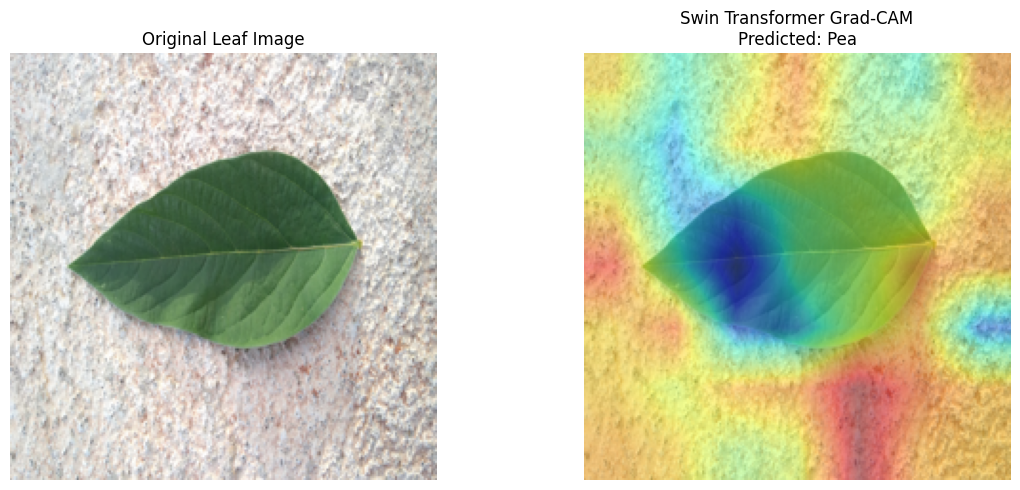

Swin heatmap statistics:
Minimum: 0.0
Maximum: 0.9999997019767761
Mean: 0.5971435904502869
Standard deviation: 0.20782434940338135


In [19]:
# ==========================================
# 17. GENERATE SWIN GRAD-CAM
# ==========================================

import torch.nn.functional as F

swin_cam, swin_pred = swin_gradcam.generate(
    swin_image_batch
)

# Upsample 7 x 7 heatmap to 224 x 224
swin_cam_resized = F.interpolate(
    swin_cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

# Original image
swin_display_image = Image.open(
    X_test[sample_idx]
).convert("RGB").resize((224, 224))

swin_display_image = np.array(swin_display_image)

# Visualize
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(swin_display_image)
plt.title("Original Leaf Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(swin_display_image)
plt.imshow(
    swin_cam_resized.squeeze().cpu().numpy(),
    cmap="jet",
    alpha=0.45
)
plt.title(
    f"Swin Transformer Grad-CAM\n"
    f"Predicted: {class_names[swin_pred]}"
)
plt.axis("off")

plt.tight_layout()
plt.show()

print("Swin heatmap statistics:")
print("Minimum:", swin_cam.min().item())
print("Maximum:", swin_cam.max().item())
print("Mean:", swin_cam.mean().item())
print("Standard deviation:", swin_cam.std().item())

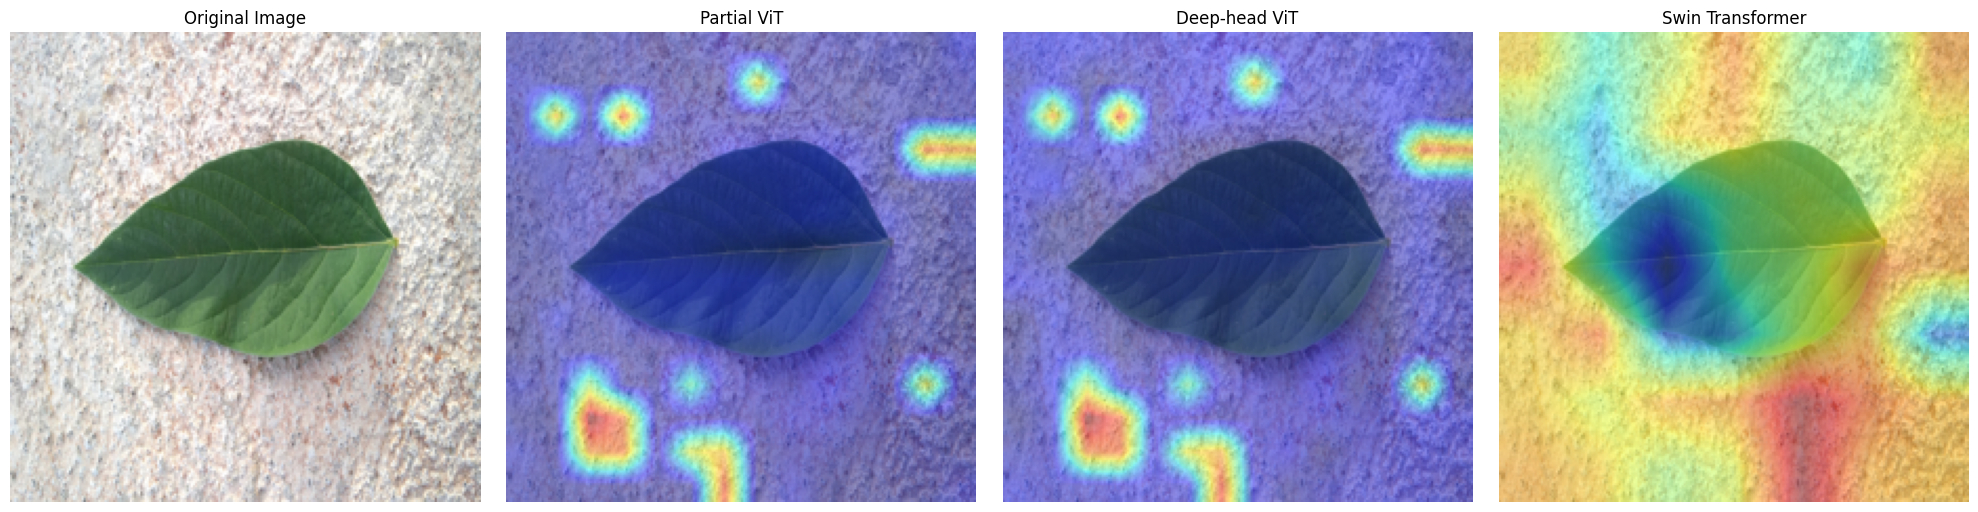

In [20]:
# ==========================================
# 18. COMPARE GRAD-CAM ACROSS ALL MODELS
# ==========================================

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Original image
axes[0].imshow(display_image)
axes[0].set_title("Original Image")

# Partial ViT
axes[1].imshow(display_image)
axes[1].imshow(
    F.interpolate(partial_cam, size=(224, 224),
                  mode="bilinear", align_corners=False)
    .squeeze().cpu().numpy(),
    cmap="jet", alpha=0.45
)
axes[1].set_title("Partial ViT")

# Deep-head ViT
axes[2].imshow(display_image)
axes[2].imshow(
    F.interpolate(deep_cam, size=(224, 224),
                  mode="bilinear", align_corners=False)
    .squeeze().cpu().numpy(),
    cmap="jet", alpha=0.45
)
axes[2].set_title("Deep-head ViT")

# Swin Transformer
axes[3].imshow(display_image)
axes[3].imshow(
    swin_cam_resized.squeeze().cpu().numpy(),
    cmap="jet", alpha=0.45
)
axes[3].set_title("Swin Transformer")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Experiment 1: Faithfulness Evaluation

This experiment evaluates how well Grad-CAM explanations identify important image regions using deletion and insertion tests. The results are compared across the three models.

In [24]:

# ==========================================
# EXPERIMENT 1: GRAD-CAM FAITHFULNESS
# Deletion and Insertion Tests
# ==========================================

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# Experiment configuration
NUM_IMAGES = 50
NUM_STEPS = 10
GRID_SIZE = 14
PATCH_SIZE = 224 // GRID_SIZE

# Models and their corresponding datasets/loaders/Grad-CAM objects
experiment_models = {
    "Partial ViT": {
        "model": vit_partial_model,
        "dataset": vit_test_dataset,
        "loader": vit_test_loader,
        "gradcam": partial_gradcam
    },
    "Deep-head ViT": {
        "model": vit_deep_model,
        "dataset": vit_test_dataset,
        "loader": vit_test_loader,
        "gradcam": deep_gradcam
    },
    "Swin Transformer": {
        "model": swin_model,
        "dataset": swin_test_dataset,
        "loader": swin_test_loader,
        "gradcam": swin_gradcam
    }
}

# ------------------------------------------
# 1. Find images correctly classified by all
#    three models
# ------------------------------------------

model_predictions = {}

for model_name, info in experiment_models.items():

    predictions = []
    info["model"].eval()

    with torch.no_grad():

        for images, labels in info["loader"]:

            images = images.to(device)

            logits = info["model"](
                pixel_values=images
            ).logits

            predictions.extend(
                logits.argmax(dim=1).cpu().numpy()
            )

    model_predictions[model_name] = np.array(predictions)


true_labels = np.array(y_test)

common_correct = np.ones(len(true_labels), dtype=bool)

for predictions in model_predictions.values():
    common_correct &= (predictions == true_labels)

common_indices = np.where(common_correct)[0]

print("Images correctly classified by all models:",
      len(common_indices))

if len(common_indices) == 0:
    raise ValueError("No common correctly classified images found.")

# Select the same deterministic subset for every model
rng = np.random.default_rng(42)

selected_indices = rng.choice(
    common_indices,
    size=min(NUM_IMAGES, len(common_indices)),
    replace=False
)

print("Images selected for faithfulness evaluation:",
      len(selected_indices))


# ------------------------------------------
# 2. Create perturbation masks from Grad-CAM
# ------------------------------------------

fractions = np.linspace(0, 1, NUM_STEPS + 1)


def create_perturbation_masks(cam):

    # Resize CAM to image dimensions
    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    # Convert to a common 14 x 14 spatial grid
    cam_grid = F.avg_pool2d(
        cam,
        kernel_size=PATCH_SIZE,
        stride=PATCH_SIZE
    )

    importance = cam_grid.flatten()
    sorted_indices = torch.argsort(
        importance,
        descending=True
    )

    masks = []

    for fraction in fractions:

        number_to_keep = int(
            round(fraction * GRID_SIZE * GRID_SIZE)
        )

        grid_mask = torch.zeros(
            GRID_SIZE * GRID_SIZE,
            device=device
        )

        grid_mask[sorted_indices[:number_to_keep]] = 1

        grid_mask = grid_mask.reshape(
            1, 1, GRID_SIZE, GRID_SIZE
        )

        pixel_mask = grid_mask.repeat_interleave(
            PATCH_SIZE, dim=2
        ).repeat_interleave(
            PATCH_SIZE, dim=3
        )

        masks.append(pixel_mask)

    return torch.cat(masks, dim=0)


# ------------------------------------------
# 3. Evaluate deletion and insertion curves
# ------------------------------------------

def evaluate_faithfulness(
    model,
    gradcam,
    dataset,
    image_index,
    model_name
):

    image, actual_label = dataset[image_index]

    image = image.unsqueeze(0).to(device)

    target_class = actual_label.item()

    # Generate Grad-CAM for the correct class
    cam, _ = gradcam.generate(
        image,
        target_class=target_class
    )

    masks = create_perturbation_masks(cam)

    # Zero in normalized input space represents
    # the processor's mean-colour baseline.
    repeated_image = image.repeat(
        len(fractions), 1, 1, 1
    )

    masks = masks.expand(-1, 3, -1, -1)

    deletion_images = repeated_image * (1 - masks)
    insertion_images = repeated_image * masks

    model.eval()

    with torch.no_grad():

        deletion_logits = model(
            pixel_values=deletion_images
        ).logits

        insertion_logits = model(
            pixel_values=insertion_images
        ).logits

        deletion_scores = torch.softmax(
            deletion_logits, dim=1
        )[:, target_class].cpu().numpy()

        insertion_scores = torch.softmax(
            insertion_logits, dim=1
        )[:, target_class].cpu().numpy()

    # Area under the confidence curves
    deletion_auc = np.trapz(
        deletion_scores, fractions
    )

    insertion_auc = np.trapz(
        insertion_scores, fractions
    )

    return {
        "Model": model_name,
        "Image_Index": image_index,
        "Class": target_class,
        "Deletion_AUC": deletion_auc,
        "Insertion_AUC": insertion_auc,
        "Deletion_Initial": deletion_scores[0],
        "Deletion_Final": deletion_scores[-1],
        "Insertion_Initial": insertion_scores[0],
        "Insertion_Final": insertion_scores[-1],
        "Deletion_Curve": deletion_scores,
        "Insertion_Curve": insertion_scores
    }


# ------------------------------------------
# 4. Run experiment on all three models
# ------------------------------------------

faithfulness_results = []

for model_name, info in experiment_models.items():

    print(f"\nEvaluating: {model_name}")

    for count, image_index in enumerate(selected_indices):

        result = evaluate_faithfulness(
            model=info["model"],
            gradcam=info["gradcam"],
            dataset=info["dataset"],
            image_index=int(image_index),
            model_name=model_name
        )

        faithfulness_results.append(result)

        if (count + 1) % 10 == 0:
            print(
                f"Processed {count + 1}/"
                f"{len(selected_indices)} images"
            )


# ------------------------------------------
# 5. Create result tables
# ------------------------------------------

faithfulness_df = pd.DataFrame(
    faithfulness_results
)

summary_df = faithfulness_df.groupby(
    "Model"
).agg(
    Mean_Deletion_AUC=("Deletion_AUC", "mean"),
    Std_Deletion_AUC=("Deletion_AUC", "std"),
    Mean_Insertion_AUC=("Insertion_AUC", "mean"),
    Std_Insertion_AUC=("Insertion_AUC", "std"),
    Images_Evaluated=("Image_Index", "count")
).reset_index()

print("\nFAITHFULNESS RESULTS")
display(
    summary_df.style.format({
        "Mean_Deletion_AUC": "{:.4f}",
        "Std_Deletion_AUC": "{:.4f}",
        "Mean_Insertion_AUC": "{:.4f}",
        "Std_Insertion_AUC": "{:.4f}"
    })
)


# ------------------------------------------
# 6. Save results
# ------------------------------------------

faithfulness_df.drop(
    columns=["Deletion_Curve", "Insertion_Curve"]
).to_csv(
    "/kaggle/working/faithfulness_individual_results.csv",
    index=False
)

summary_df.to_csv(
    "/kaggle/working/faithfulness_summary.csv",
    index=False
)

print("\nFaithfulness experiment completed.")
print("Individual results and summary saved.")


Images correctly classified by all models: 627
Images selected for faithfulness evaluation: 50

Evaluating: Partial ViT


/tmp/ipykernel_50/1652079280.py:214: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  deletion_auc = np.trapz(
/tmp/ipykernel_50/1652079280.py:218: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  insertion_auc = np.trapz(


Processed 10/50 images
Processed 20/50 images
Processed 30/50 images
Processed 40/50 images
Processed 50/50 images

Evaluating: Deep-head ViT
Processed 10/50 images
Processed 20/50 images
Processed 30/50 images
Processed 40/50 images
Processed 50/50 images

Evaluating: Swin Transformer
Processed 10/50 images
Processed 20/50 images
Processed 30/50 images
Processed 40/50 images
Processed 50/50 images

FAITHFULNESS RESULTS


,Model,Mean_Deletion_AUC,Std_Deletion_AUC,Mean_Insertion_AUC,Std_Insertion_AUC,Images_Evaluated
0,Deep-head ViT,0.4891,0.2734,0.4219,0.2844,50
1,Partial ViT,0.4600,0.2607,0.3279,0.2031,50
2,Swin Transformer,0.6730,0.2414,0.6772,0.2409,50



Faithfulness experiment completed.
Individual results and summary saved.


In [25]:

# ==========================================
# EXPERIMENT 1: STATISTICAL COMPARISON
# ==========================================

from scipy.stats import wilcoxon
from itertools import combinations
import numpy as np
import pandas as pd

metrics = ["Deletion_AUC", "Insertion_AUC"]

model_names = faithfulness_df["Model"].unique().tolist()

statistical_results = []

for metric in metrics:

    for model_a, model_b in combinations(model_names, 2):

        paired = faithfulness_df.pivot(
            index="Image_Index",
            columns="Model",
            values=metric
        )[[model_a, model_b]].dropna()

        values_a = paired[model_a].values
        values_b = paired[model_b].values

        statistic, p_value = wilcoxon(
            values_a,
            values_b,
            alternative="two-sided"
        )

        differences = values_a - values_b

        rng = np.random.default_rng(42)
        bootstrap_means = []

        for _ in range(5000):
            sample = rng.choice(
                differences,
                size=len(differences),
                replace=True
            )
            bootstrap_means.append(sample.mean())

        ci_lower, ci_upper = np.percentile(
            bootstrap_means, [2.5, 97.5]
        )

        statistical_results.append({
            "Metric": metric,
            "Model_A": model_a,
            "Model_B": model_b,
            "Mean_Difference_A_minus_B": differences.mean(),
            "CI_95_Lower": ci_lower,
            "CI_95_Upper": ci_upper,
            "Wilcoxon_p_value": p_value
        })

stats_df = pd.DataFrame(statistical_results)

# Holm correction for multiple comparisons
p_values = stats_df["Wilcoxon_p_value"].values
order = np.argsort(p_values)
adjusted = np.empty(len(p_values))

running_max = 0

for rank, index in enumerate(order):
    corrected = min(
        1.0,
        (len(p_values) - rank) * p_values[index]
    )
    running_max = max(running_max, corrected)
    adjusted[index] = running_max

stats_df["Holm_Adjusted_p"] = adjusted

display(
    stats_df.style.format({
        "Mean_Difference_A_minus_B": "{:.4f}",
        "CI_95_Lower": "{:.4f}",
        "CI_95_Upper": "{:.4f}",
        "Wilcoxon_p_value": "{:.6f}",
        "Holm_Adjusted_p": "{:.6f}"
    })
)

stats_df.to_csv(
    "/kaggle/working/faithfulness_statistical_comparison.csv",
    index=False
)

print("Statistical comparison completed.")


,Metric,Model_A,Model_B,Mean_Difference_A_minus_B,CI_95_Lower,CI_95_Upper,Wilcoxon_p_value,Holm_Adjusted_p
0,Deletion_AUC,Partial ViT,Deep-head ViT,-0.0291,-0.1240,0.0692,0.454788,0.454788
1,Deletion_AUC,Partial ViT,Swin Transformer,-0.2129,-0.3181,-0.1084,0.000551,0.001653
2,Deletion_AUC,Deep-head ViT,Swin Transformer,-0.1838,-0.2795,-0.0919,0.000241,0.000964
3,Insertion_AUC,Partial ViT,Deep-head ViT,-0.0940,-0.1961,0.0084,0.140684,0.281368
4,Insertion_AUC,Partial ViT,Swin Transformer,-0.3493,-0.4424,-0.2568,0.000000,0.000000
5,Insertion_AUC,Deep-head ViT,Swin Transformer,-0.2553,-0.3570,-0.1534,0.000012,0.000058


Statistical comparison completed.


## 6. Experiment 2: Robustness Evaluation

This experiment evaluates the stability of Grad-CAM explanations under different input image transformations: brightness adjustment, Gaussian blur, and Gaussian noise. Explanation similarity is measured using Structural Similarity Index (SSIM), while prediction consistency is also examined.

In [26]:

# ==========================================
# EXPERIMENT 2: GRAD-CAM ROBUSTNESS
# Brightness, Gaussian Noise and Blur
# ==========================================

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from skimage.metrics import structural_similarity

# ------------------------------------------
# 1. Define image transformations
# ------------------------------------------

def apply_brightness(image):
    # Small brightness increase in normalized space
    return image + 0.15


def apply_gaussian_noise(image):
    generator = torch.Generator(device=image.device)
    generator.manual_seed(42)

    noise = torch.randn(
        image.shape,
        generator=generator,
        device=image.device,
        dtype=image.dtype
    ) * 0.05

    return image + noise


def apply_gaussian_blur(image):

    coordinates = torch.arange(
        -2, 3, device=image.device, dtype=image.dtype
    )

    kernel_1d = torch.exp(
        -(coordinates ** 2) / (2 * 1.0 ** 2)
    )

    kernel_1d = kernel_1d / kernel_1d.sum()

    kernel_2d = torch.outer(kernel_1d, kernel_1d)
    kernel_2d = kernel_2d / kernel_2d.sum()

    kernel = kernel_2d.expand(
        image.shape[1], 1, 5, 5
    )

    return F.conv2d(
        image,
        kernel,
        padding=2,
        groups=image.shape[1]
    )


transformations = {
    "Brightness": apply_brightness,
    "Gaussian Noise": apply_gaussian_noise,
    "Gaussian Blur": apply_gaussian_blur
}


# ------------------------------------------
# 2. Generate normalized Grad-CAM heatmaps
# ------------------------------------------

def generate_normalized_cam(gradcam, image, target_class):

    cam, _ = gradcam.generate(
        image,
        target_class=target_class
    )

    if cam.ndim == 2:
        cam = cam.unsqueeze(0).unsqueeze(0)
    elif cam.ndim == 3:
        cam = cam.unsqueeze(0)

    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = cam.squeeze().detach().cpu().numpy()

    cam = np.maximum(cam, 0)

    minimum = cam.min()
    maximum = cam.max()

    if maximum - minimum < 1e-8:
        return np.zeros_like(cam, dtype=np.float32)

    return (
        (cam - minimum) / (maximum - minimum)
    ).astype(np.float32)


# ------------------------------------------
# 3. Calculate explanation similarity
# ------------------------------------------

robustness_results = []

for model_name, info in experiment_models.items():

    model = info["model"]
    gradcam = info["gradcam"]
    dataset = info["dataset"]

    model.eval()

    print(f"\nEvaluating: {model_name}")

    for count, image_index in enumerate(selected_indices):

        image, actual_label = dataset[int(image_index)]

        image = image.unsqueeze(0).to(device)
        target_class = actual_label.item()

        # Original explanation
        original_cam = generate_normalized_cam(
            gradcam, image, target_class
        )

        for transform_name, transform_function in transformations.items():

            transformed_image = transform_function(image)

            transformed_cam = generate_normalized_cam(
                gradcam,
                transformed_image,
                target_class
            )

            similarity = structural_similarity(
                original_cam,
                transformed_cam,
                data_range=1.0
            )

            robustness_results.append({
                "Model": model_name,
                "Image_Index": int(image_index),
                "Transformation": transform_name,
                "SSIM": similarity
            })

        if (count + 1) % 10 == 0:
            print(
                f"Processed {count + 1}/"
                f"{len(selected_indices)} images"
            )


# ------------------------------------------
# 4. Summarize robustness results
# ------------------------------------------

robustness_df = pd.DataFrame(robustness_results)

robustness_summary = robustness_df.groupby(
    ["Model", "Transformation"]
).agg(
    Mean_SSIM=("SSIM", "mean"),
    Std_SSIM=("SSIM", "std"),
    Images_Evaluated=("Image_Index", "count")
).reset_index()

print("\nGRAD-CAM ROBUSTNESS RESULTS")

display(
    robustness_summary.style.format({
        "Mean_SSIM": "{:.4f}",
        "Std_SSIM": "{:.4f}"
    })
)


# ------------------------------------------
# 5. Save results
# ------------------------------------------

robustness_df.to_csv(
    "/kaggle/working/robustness_individual_results.csv",
    index=False
)

robustness_summary.to_csv(
    "/kaggle/working/robustness_summary.csv",
    index=False
)

print("\nRobustness experiment completed.")
print("Individual results and summary saved.")



Evaluating: Partial ViT
Processed 10/50 images
Processed 20/50 images
Processed 30/50 images
Processed 40/50 images
Processed 50/50 images

Evaluating: Deep-head ViT
Processed 10/50 images
Processed 20/50 images
Processed 30/50 images
Processed 40/50 images
Processed 50/50 images

Evaluating: Swin Transformer
Processed 10/50 images
Processed 20/50 images
Processed 30/50 images
Processed 40/50 images
Processed 50/50 images

GRAD-CAM ROBUSTNESS RESULTS


,Model,Transformation,Mean_SSIM,Std_SSIM,Images_Evaluated
0,Deep-head ViT,Brightness,0.8930,0.1542,50
1,Deep-head ViT,Gaussian Blur,0.5408,0.2804,50
2,Deep-head ViT,Gaussian Noise,0.5710,0.2821,50
3,Partial ViT,Brightness,0.9087,0.1272,50
4,Partial ViT,Gaussian Blur,0.6468,0.2253,50
5,Partial ViT,Gaussian Noise,0.5557,0.2550,50
6,Swin Transformer,Brightness,0.9927,0.0069,50
7,Swin Transformer,Gaussian Blur,0.6925,0.0956,50
8,Swin Transformer,Gaussian Noise,0.7594,0.1357,50



Robustness experiment completed.
Individual results and summary saved.


In [27]:

# ==========================================
# ROBUSTNESS VALIDATION
# Common CAM resolution + prediction stability
# ==========================================

from skimage.metrics import structural_similarity
import torch.nn.functional as F
import numpy as np
import pandas as pd
import torch

validation_results = []

def generate_cam_14(gradcam, image, target_class):

    cam, _ = gradcam.generate(
        image,
        target_class=target_class
    )

    if cam.ndim == 2:
        cam = cam.unsqueeze(0).unsqueeze(0)
    elif cam.ndim == 3:
        cam = cam.unsqueeze(0)

    cam = F.interpolate(
        cam,
        size=(14, 14),
        mode="bilinear",
        align_corners=False
    )

    cam = cam.squeeze().detach().cpu().numpy()
    cam = np.maximum(cam, 0)

    minimum, maximum = cam.min(), cam.max()

    if maximum - minimum < 1e-8:
        return np.zeros_like(cam, dtype=np.float32)

    return ((cam - minimum) / (maximum - minimum)).astype(np.float32)


for model_name, info in experiment_models.items():

    model = info["model"]
    gradcam = info["gradcam"]
    dataset = info["dataset"]

    model.eval()

    print(f"\nValidating: {model_name}")

    for image_index in selected_indices:

        image, actual_label = dataset[int(image_index)]
        image = image.unsqueeze(0).to(device)
        target_class = actual_label.item()

        original_cam = generate_cam_14(
            gradcam, image, target_class
        )

        for transform_name, transform_function in transformations.items():

            transformed_image = transform_function(image)

            transformed_cam = generate_cam_14(
                gradcam,
                transformed_image,
                target_class
            )

            similarity = structural_similarity(
                original_cam,
                transformed_cam,
                data_range=1.0
            )

            with torch.no_grad():

                transformed_prediction = model(
                    pixel_values=transformed_image
                ).logits.argmax(dim=1).item()

            validation_results.append({
                "Model": model_name,
                "Image_Index": int(image_index),
                "Transformation": transform_name,
                "SSIM_14x14": similarity,
                "Prediction_Preserved": (
                    transformed_prediction == target_class
                )
            })


validation_df = pd.DataFrame(validation_results)

validation_summary = validation_df.groupby(
    ["Model", "Transformation"]
).agg(
    Mean_SSIM_14x14=("SSIM_14x14", "mean"),
    Std_SSIM_14x14=("SSIM_14x14", "std"),
    Prediction_Consistency=("Prediction_Preserved", "mean"),
    Images_Evaluated=("Image_Index", "count")
).reset_index()

display(
    validation_summary.style.format({
        "Mean_SSIM_14x14": "{:.4f}",
        "Std_SSIM_14x14": "{:.4f}",
        "Prediction_Consistency": "{:.2%}"
    })
)

validation_df.to_csv(
    "/kaggle/working/robustness_validation_individual.csv",
    index=False
)

validation_summary.to_csv(
    "/kaggle/working/robustness_validation_summary.csv",
    index=False
)

print("\nRobustness validation completed.")



Validating: Partial ViT

Validating: Deep-head ViT

Validating: Swin Transformer


,Model,Transformation,Mean_SSIM_14x14,Std_SSIM_14x14,Prediction_Consistency,Images_Evaluated
0,Deep-head ViT,Brightness,0.8707,0.2327,98.00%,50
1,Deep-head ViT,Gaussian Blur,0.3563,0.3111,94.00%,50
2,Deep-head ViT,Gaussian Noise,0.3971,0.3091,96.00%,50
3,Partial ViT,Brightness,0.9143,0.1833,100.00%,50
4,Partial ViT,Gaussian Blur,0.5428,0.2488,96.00%,50
5,Partial ViT,Gaussian Noise,0.4342,0.3213,98.00%,50
6,Swin Transformer,Brightness,0.9923,0.0110,100.00%,50
7,Swin Transformer,Gaussian Blur,0.5303,0.2270,88.00%,50
8,Swin Transformer,Gaussian Noise,0.6569,0.2426,78.00%,50



Robustness validation completed.


## 7. Statistical Analysis

Statistical tests are conducted to determine whether the observed differences between models are significant. Paired Wilcoxon signed-rank tests, McNemar tests, bootstrap confidence intervals, and Holm correction are used where appropriate.

In [29]:

from scipy.stats import wilcoxon, binomtest
from itertools import combinations
from statsmodels.stats.multitest import multipletests
import pandas as pd
import numpy as np

ssim_tests = []
prediction_tests = []

models = validation_df["Model"].unique()
transformations_list = validation_df["Transformation"].unique()

for transformation in transformations_list:
    subset = validation_df[
        validation_df["Transformation"] == transformation
    ]

    for model_a, model_b in combinations(models, 2):
        a = subset[subset["Model"] == model_a].set_index("Image_Index")
        b = subset[subset["Model"] == model_b].set_index("Image_Index")

        common = a.index.intersection(b.index)
        a = a.loc[common]
        b = b.loc[common]

        # Paired SSIM comparison
        differences = a["SSIM_14x14"] - b["SSIM_14x14"]

        if not np.allclose(differences, 0):
            stat, p_value = wilcoxon(
                a["SSIM_14x14"],
                b["SSIM_14x14"]
            )
        else:
            stat, p_value = 0, 1.0

        ssim_tests.append({
            "Transformation": transformation,
            "Model_A": model_a,
            "Model_B": model_b,
            "Mean_Difference_A_minus_B": differences.mean(),
            "Wilcoxon_p": p_value,
            "Images_Paired": len(common)
        })

        # Paired prediction-preservation comparison
        preserved_a = a["Prediction_Preserved"].astype(bool).to_numpy()
        preserved_b = b["Prediction_Preserved"].astype(bool).to_numpy()

        a_only = np.sum(preserved_a & ~preserved_b)
        b_only = np.sum(~preserved_a & preserved_b)

        discordant = a_only + b_only

        if discordant == 0:
            prediction_p = 1.0
        else:
            prediction_p = binomtest(
                min(a_only, b_only),
                discordant,
                p=0.5,
                alternative="two-sided"
            ).pvalue

        prediction_tests.append({
            "Transformation": transformation,
            "Model_A": model_a,
            "Model_B": model_b,
            "Preserved_A_only": a_only,
            "Preserved_B_only": b_only,
            "McNemar_p": prediction_p,
            "Images_Paired": len(common)
        })

# Holm correction across all nine comparisons for each outcome
ssim_results = pd.DataFrame(ssim_tests)
prediction_results = pd.DataFrame(prediction_tests)

ssim_results["Holm_p"] = multipletests(
    ssim_results["Wilcoxon_p"], method="holm"
)[1]

prediction_results["Holm_p"] = multipletests(
    prediction_results["McNemar_p"], method="holm"
)[1]

ssim_results["Significant"] = ssim_results["Holm_p"] < 0.05
prediction_results["Significant"] = prediction_results["Holm_p"] < 0.05

ssim_results.to_csv(
    "/kaggle/working/robustness_ssim_statistical_tests.csv",
    index=False
)

prediction_results.to_csv(
    "/kaggle/working/robustness_prediction_statistical_tests.csv",
    index=False
)

print("SSIM Statistical Comparisons")
display(ssim_results.round(5))

print("\nPrediction Preservation Statistical Comparisons")
display(prediction_results.round(5))

print("\nStatistical analysis completed.")


SSIM Statistical Comparisons


,Transformation,Model_A,Model_B,Mean_Difference_A_minus_B,Wilcoxon_p,Images_Paired,Holm_p,Significant
0,Brightness,Partial ViT,Deep-head ViT,0.04370,0.16293,50,0.48880,False
1,Brightness,Partial ViT,Swin Transformer,-0.07799,0.00000,50,0.00000,True
2,Brightness,Deep-head ViT,Swin Transformer,-0.12169,0.00000,50,0.00000,True
3,Gaussian Noise,Partial ViT,Deep-head ViT,0.03708,0.46647,50,0.93295,False
4,Gaussian Noise,Partial ViT,Swin Transformer,-0.22274,0.00024,50,0.00145,True
5,Gaussian Noise,Deep-head ViT,Swin Transformer,-0.25982,0.00001,50,0.00008,True
6,Gaussian Blur,Partial ViT,Deep-head ViT,0.18642,0.00476,50,0.01903,True
7,Gaussian Blur,Partial ViT,Swin Transformer,0.01240,0.97710,50,0.97710,False
8,Gaussian Blur,Deep-head ViT,Swin Transformer,-0.17401,0.00172,50,0.00858,True



Prediction Preservation Statistical Comparisons


,Transformation,Model_A,Model_B,Preserved_A_only,Preserved_B_only,McNemar_p,Images_Paired,Holm_p,Significant
0,Brightness,Partial ViT,Deep-head ViT,1,0,1.00000,50,1.00000,False
1,Brightness,Partial ViT,Swin Transformer,0,0,1.00000,50,1.00000,False
2,Brightness,Deep-head ViT,Swin Transformer,0,1,1.00000,50,1.00000,False
3,Gaussian Noise,Partial ViT,Deep-head ViT,1,0,1.00000,50,1.00000,False
4,Gaussian Noise,Partial ViT,Swin Transformer,11,1,0.00635,50,0.05713,False
5,Gaussian Noise,Deep-head ViT,Swin Transformer,11,2,0.02246,50,0.17969,False
6,Gaussian Blur,Partial ViT,Deep-head ViT,2,1,1.00000,50,1.00000,False
7,Gaussian Blur,Partial ViT,Swin Transformer,5,1,0.21875,50,1.00000,False
8,Gaussian Blur,Deep-head ViT,Swin Transformer,5,2,0.45312,50,1.00000,False



Statistical analysis completed.


In [30]:
print("Available result dataframes:")

for name in [
    "evaluation_results",
    "faithfulness_summary",
    "validation_summary",
    "ssim_results",
    "prediction_results"
]:
    if name in globals():
        print(f"\n{name}:")
        display(globals()[name])
    else:
        print(f"{name}: Not found")

Available result dataframes:
evaluation_results: Not found
faithfulness_summary: Not found

validation_summary:


,Model,Transformation,Mean_SSIM_14x14,Std_SSIM_14x14,Prediction_Consistency,Images_Evaluated
0,Deep-head ViT,Brightness,0.870650,0.232655,0.98,50
1,Deep-head ViT,Gaussian Blur,0.356333,0.311149,0.94,50
2,Deep-head ViT,Gaussian Noise,0.397112,0.309098,0.96,50
3,Partial ViT,Brightness,0.914350,0.183348,1.00,50
4,Partial ViT,Gaussian Blur,0.542750,0.248797,0.96,50
5,Partial ViT,Gaussian Noise,0.434191,0.321254,0.98,50
6,Swin Transformer,Brightness,0.992342,0.010999,1.00,50
7,Swin Transformer,Gaussian Blur,0.530346,0.227022,0.88,50
8,Swin Transformer,Gaussian Noise,0.656931,0.242632,0.78,50



ssim_results:


,Transformation,Model_A,Model_B,Mean_Difference_A_minus_B,Wilcoxon_p,Images_Paired,Holm_p,Significant
0,Brightness,Partial ViT,Deep-head ViT,0.043700,1.629323e-01,50,4.887968e-01,False
1,Brightness,Partial ViT,Swin Transformer,-0.077992,9.521273e-13,50,8.569145e-12,True
2,Brightness,Deep-head ViT,Swin Transformer,-0.121692,8.060397e-11,50,6.448317e-10,True
3,Gaussian Noise,Partial ViT,Deep-head ViT,0.037079,4.664730e-01,50,9.329461e-01,False
4,Gaussian Noise,Partial ViT,Swin Transformer,-0.222740,2.409992e-04,50,1.445995e-03,True
5,Gaussian Noise,Deep-head ViT,Swin Transformer,-0.259819,1.103369e-05,50,7.723582e-05,True
6,Gaussian Blur,Partial ViT,Deep-head ViT,0.186418,4.757047e-03,50,1.902819e-02,True
7,Gaussian Blur,Partial ViT,Swin Transformer,0.012404,9.771032e-01,50,9.771032e-01,False
8,Gaussian Blur,Deep-head ViT,Swin Transformer,-0.174014,1.715436e-03,50,8.577180e-03,True



prediction_results:


,Transformation,Model_A,Model_B,Preserved_A_only,Preserved_B_only,McNemar_p,Images_Paired,Holm_p,Significant
0,Brightness,Partial ViT,Deep-head ViT,1,0,1.000000,50,1.000000,False
1,Brightness,Partial ViT,Swin Transformer,0,0,1.000000,50,1.000000,False
2,Brightness,Deep-head ViT,Swin Transformer,0,1,1.000000,50,1.000000,False
3,Gaussian Noise,Partial ViT,Deep-head ViT,1,0,1.000000,50,1.000000,False
4,Gaussian Noise,Partial ViT,Swin Transformer,11,1,0.006348,50,0.057129,False
5,Gaussian Noise,Deep-head ViT,Swin Transformer,11,2,0.022461,50,0.179688,False
6,Gaussian Blur,Partial ViT,Deep-head ViT,2,1,1.000000,50,1.000000,False
7,Gaussian Blur,Partial ViT,Swin Transformer,5,1,0.218750,50,1.000000,False
8,Gaussian Blur,Deep-head ViT,Swin Transformer,5,2,0.453125,50,1.000000,False


## 8. Research Visualizations

This section presents visual comparisons of model classification performance, faithfulness, explanation robustness, and prediction consistency.

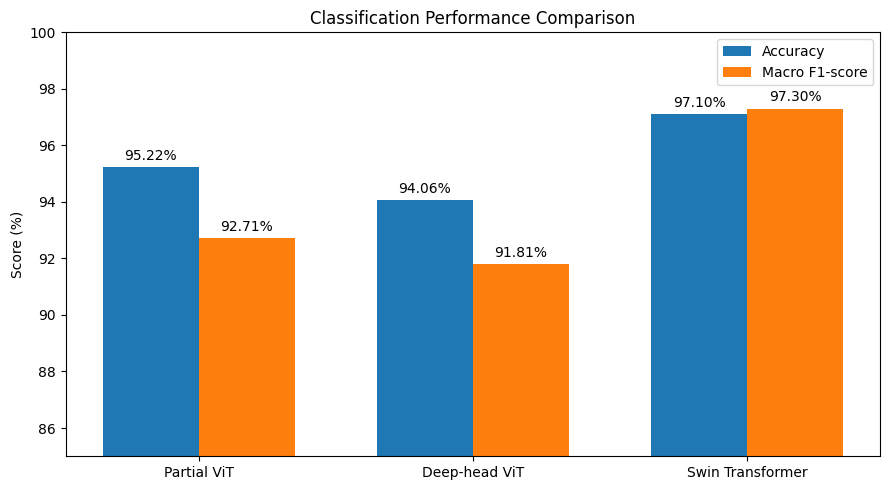

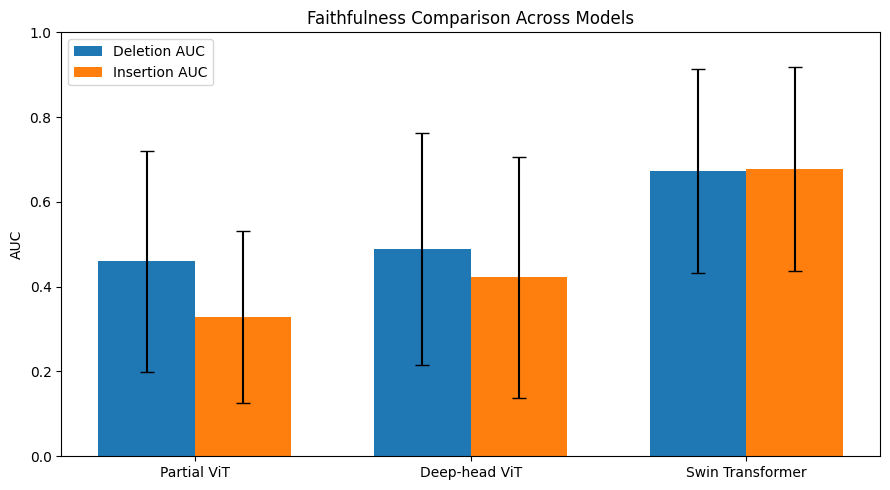

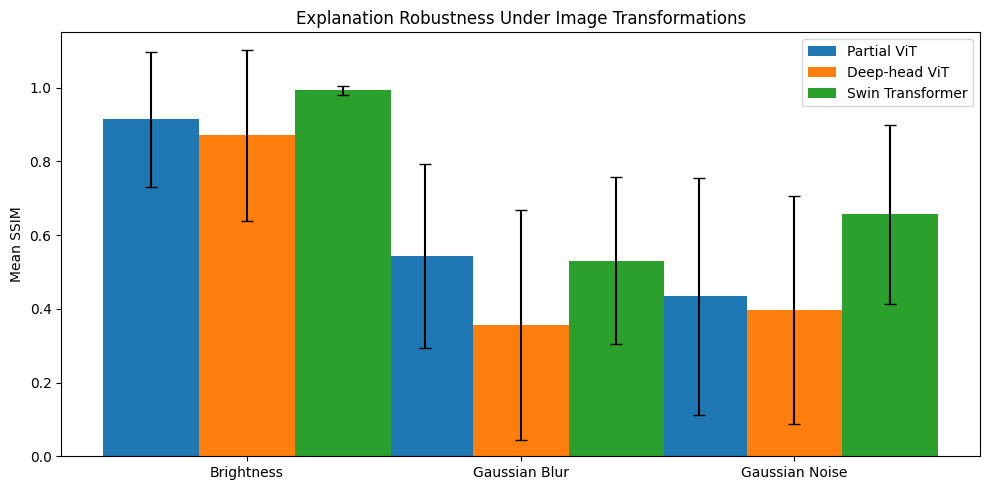

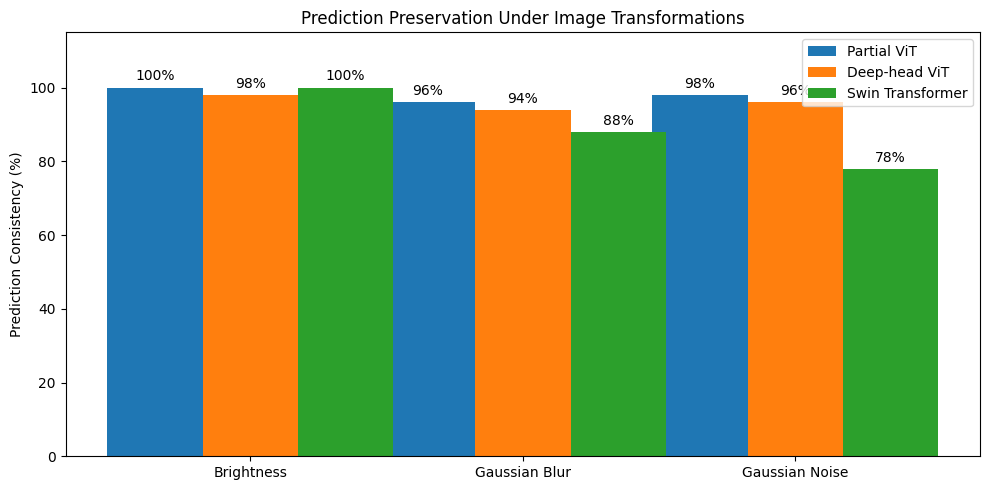

All four research figures generated successfully.
Saved in: /kaggle/working/research_figures

Generated files:
figure1_model_performance.pdf
figure1_model_performance.png
figure2_faithfulness.pdf
figure2_faithfulness.png
figure3_explanation_robustness.pdf
figure3_explanation_robustness.png
figure4_prediction_robustness.pdf
figure4_prediction_robustness.png


In [31]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create output directory
output_dir = "/kaggle/working/research_figures"
os.makedirs(output_dir, exist_ok=True)

models = ["Partial ViT", "Deep-head ViT", "Swin Transformer"]
x = np.arange(len(models))
width = 0.35

# --------------------------------------------------
# FIGURE 1: MODEL PERFORMANCE
# --------------------------------------------------

accuracy = [95.22, 94.06, 97.10]
macro_f1 = [92.71, 91.81, 97.30]

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width/2, accuracy, width, label="Accuracy")
bars2 = ax.bar(x + width/2, macro_f1, width, label="Macro F1-score")

ax.set_title("Classification Performance Comparison")
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(85, 100)
ax.legend()

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig(f"{output_dir}/figure1_model_performance.png", dpi=300)
plt.savefig(f"{output_dir}/figure1_model_performance.pdf")
plt.show()


# --------------------------------------------------
# FIGURE 2: FAITHFULNESS
# --------------------------------------------------

deletion = [0.4600, 0.4891, 0.6730]
deletion_std = [0.2607, 0.2734, 0.2414]

insertion = [0.3279, 0.4219, 0.6772]
insertion_std = [0.2031, 0.2844, 0.2409]

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width/2, deletion, width,
    yerr=deletion_std, capsize=5,
    label="Deletion AUC"
)

ax.bar(
    x + width/2, insertion, width,
    yerr=insertion_std, capsize=5,
    label="Insertion AUC"
)

ax.set_title("Faithfulness Comparison Across Models")
ax.set_ylabel("AUC")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1)
ax.legend()

plt.tight_layout()
plt.savefig(f"{output_dir}/figure2_faithfulness.png", dpi=300)
plt.savefig(f"{output_dir}/figure2_faithfulness.pdf")
plt.show()


# --------------------------------------------------
# FIGURE 3: EXPLANATION ROBUSTNESS (SSIM)
# --------------------------------------------------

transformations = ["Brightness", "Gaussian Blur", "Gaussian Noise"]

ssim_data = {
    "Partial ViT": [0.914350, 0.542750, 0.434191],
    "Deep-head ViT": [0.870650, 0.356333, 0.397112],
    "Swin Transformer": [0.992342, 0.530346, 0.656931]
}

ssim_std = {
    "Partial ViT": [0.183348, 0.248797, 0.321254],
    "Deep-head ViT": [0.232655, 0.311149, 0.309098],
    "Swin Transformer": [0.010999, 0.227022, 0.242632]
}

fig, ax = plt.subplots(figsize=(10, 5))

for i, model in enumerate(models):
    positions = np.arange(len(transformations)) + (i - 1) * width

    ax.bar(
        positions,
        ssim_data[model],
        width,
        yerr=ssim_std[model],
        capsize=4,
        label=model
    )

ax.set_title("Explanation Robustness Under Image Transformations")
ax.set_ylabel("Mean SSIM")
ax.set_xticks(np.arange(len(transformations)))
ax.set_xticklabels(transformations)
ax.set_ylim(0, 1.15)
ax.legend()

plt.tight_layout()
plt.savefig(f"{output_dir}/figure3_explanation_robustness.png", dpi=300)
plt.savefig(f"{output_dir}/figure3_explanation_robustness.pdf")
plt.show()


# --------------------------------------------------
# FIGURE 4: PREDICTION ROBUSTNESS
# --------------------------------------------------

prediction_data = {
    "Partial ViT": [100, 96, 98],
    "Deep-head ViT": [98, 94, 96],
    "Swin Transformer": [100, 88, 78]
}

fig, ax = plt.subplots(figsize=(10, 5))

for i, model in enumerate(models):
    positions = np.arange(len(transformations)) + (i - 1) * width

    bars = ax.bar(
        positions,
        prediction_data[model],
        width,
        label=model
    )

    ax.bar_label(bars, fmt="%.0f%%", padding=3)

ax.set_title("Prediction Preservation Under Image Transformations")
ax.set_ylabel("Prediction Consistency (%)")
ax.set_xticks(np.arange(len(transformations)))
ax.set_xticklabels(transformations)
ax.set_ylim(0, 115)
ax.legend()

plt.tight_layout()
plt.savefig(f"{output_dir}/figure4_prediction_robustness.png", dpi=300)
plt.savefig(f"{output_dir}/figure4_prediction_robustness.pdf")
plt.show()


# --------------------------------------------------
# COMPLETION
# --------------------------------------------------

print("All four research figures generated successfully.")
print("Saved in:", output_dir)
print("\nGenerated files:")

for filename in sorted(os.listdir(output_dir)):
    print(filename)


## 9. Combined Results and Model Comparison

This section consolidates the classification performance, faithfulness metrics, explanation stability, and prediction consistency results to provide an overall comparison of the three models.

In [32]:

final_results = pd.DataFrame({
    "Model": [
        "Partial ViT",
        "Deep-head ViT",
        "Swin Transformer"
    ],
    "Accuracy (%)": [95.22, 94.06, 97.10],
    "Macro F1 (%)": [92.71, 91.81, 97.30],
    "Deletion AUC": [0.4600, 0.4891, 0.6730],
    "Insertion AUC": [0.3279, 0.4219, 0.6772],
    "Brightness SSIM": [0.9144, 0.8707, 0.9923],
    "Blur SSIM": [0.5428, 0.3563, 0.5303],
    "Noise SSIM": [0.4342, 0.3971, 0.6569],
    "Brightness Consistency (%)": [100, 98, 100],
    "Blur Consistency (%)": [96, 94, 88],
    "Noise Consistency (%)": [98, 96, 78]
})

display(final_results.round(4))

final_results.to_csv(
    "/kaggle/working/final_combined_results.csv",
    index=False
)

print("Consolidated results saved successfully.")


,Model,Accuracy (%),Macro F1 (%),Deletion AUC,Insertion AUC,Brightness SSIM,Blur SSIM,Noise SSIM,Brightness Consistency (%),Blur Consistency (%),Noise Consistency (%)
0,Partial ViT,95.22,92.71,0.4600,0.3279,0.9144,0.5428,0.4342,100,96,98
1,Deep-head ViT,94.06,91.81,0.4891,0.4219,0.8707,0.3563,0.3971,98,94,96
2,Swin Transformer,97.10,97.30,0.6730,0.6772,0.9923,0.5303,0.6569,100,88,78


Consolidated results saved successfully.


In [33]:

import os

working_dir = "/kaggle/working"

expected_files = [
    "faithfulness_individual_results.csv",
    "faithfulness_summary.csv",
    "faithfulness_statistical_comparison.csv",
    "robustness_individual_results.csv",
    "robustness_summary.csv",
    "robustness_validation_individual.csv",
    "robustness_validation_summary.csv",
    "robustness_ssim_statistical_tests.csv",
    "robustness_prediction_statistical_tests.csv",
    "final_combined_results.csv"
]

print("RESEARCH FILE VERIFICATION")
print("-" * 55)

for filename in expected_files:
    path = os.path.join(working_dir, filename)

    if os.path.exists(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"[FOUND]   {filename} ({size_kb:.2f} KB)")
    else:
        print(f"[MISSING] {filename}")

print("\nRESEARCH FIGURES")
print("-" * 55)

figures_dir = os.path.join(working_dir, "research_figures")

if os.path.exists(figures_dir):
    for filename in sorted(os.listdir(figures_dir)):
        print("[FOUND]", filename)
else:
    print("Research figures folder not found.")


RESEARCH FILE VERIFICATION
-------------------------------------------------------
[FOUND]   faithfulness_individual_results.csv (15.34 KB)
[FOUND]   faithfulness_summary.csv (0.37 KB)
[FOUND]   faithfulness_statistical_comparison.csv (0.96 KB)
[FOUND]   robustness_individual_results.csv (22.24 KB)
[FOUND]   robustness_summary.csv (0.67 KB)
[FOUND]   robustness_validation_individual.csv (24.59 KB)
[FOUND]   robustness_validation_summary.csv (0.74 KB)
[FOUND]   robustness_ssim_statistical_tests.csv (1.09 KB)
[FOUND]   robustness_prediction_statistical_tests.csv (0.70 KB)
[FOUND]   final_combined_results.csv (0.37 KB)

RESEARCH FIGURES
-------------------------------------------------------
[FOUND] figure1_model_performance.pdf
[FOUND] figure1_model_performance.png
[FOUND] figure2_faithfulness.pdf
[FOUND] figure2_faithfulness.png
[FOUND] figure3_explanation_robustness.pdf
[FOUND] figure3_explanation_robustness.png
[FOUND] figure4_prediction_robustness.pdf
[FOUND] figure4_prediction_robus

In [34]:

import os
import pandas as pd

files_to_check = [
    "faithfulness_individual_results.csv",
    "faithfulness_summary.csv",
    "faithfulness_statistical_comparison.csv",
    "robustness_individual_results.csv",
    "robustness_summary.csv",
    "robustness_validation_individual.csv",
    "robustness_validation_summary.csv",
    "robustness_ssim_statistical_tests.csv",
    "robustness_prediction_statistical_tests.csv",
    "final_combined_results.csv"
]

print("CSV CONTENT VERIFICATION")
print("=" * 65)

for filename in files_to_check:
    path = f"/kaggle/working/{filename}"
    df = pd.read_csv(path)

    print(f"\n{filename}")
    print("Rows:", len(df))
    print("Columns:", list(df.columns))
    print("Missing values:", df.isnull().sum().sum())

print("\nVerification completed.")


CSV CONTENT VERIFICATION

faithfulness_individual_results.csv
Rows: 150
Columns: ['Model', 'Image_Index', 'Class', 'Deletion_AUC', 'Insertion_AUC', 'Deletion_Initial', 'Deletion_Final', 'Insertion_Initial', 'Insertion_Final']
Missing values: 0

faithfulness_summary.csv
Rows: 3
Columns: ['Model', 'Mean_Deletion_AUC', 'Std_Deletion_AUC', 'Mean_Insertion_AUC', 'Std_Insertion_AUC', 'Images_Evaluated']
Missing values: 0

faithfulness_statistical_comparison.csv
Rows: 6
Columns: ['Metric', 'Model_A', 'Model_B', 'Mean_Difference_A_minus_B', 'CI_95_Lower', 'CI_95_Upper', 'Wilcoxon_p_value', 'Holm_Adjusted_p']
Missing values: 0

robustness_individual_results.csv
Rows: 450
Columns: ['Model', 'Image_Index', 'Transformation', 'SSIM']
Missing values: 0

robustness_summary.csv
Rows: 9
Columns: ['Model', 'Transformation', 'Mean_SSIM', 'Std_SSIM', 'Images_Evaluated']
Missing values: 0

robustness_validation_individual.csv
Rows: 450
Columns: ['Model', 'Image_Index', 'Transformation', 'SSIM_14x14', 'Pred

In [36]:
import os
import zipfile

working_dir = "/kaggle/working"
zip_path = os.path.join(
    working_dir,
    "GradCAM_Research_Results_Backup.zip"
)

csv_files = [
    "faithfulness_individual_results.csv",
    "faithfulness_summary.csv",
    "faithfulness_statistical_comparison.csv",
    "robustness_individual_results.csv",
    "robustness_summary.csv",
    "robustness_validation_individual.csv",
    "robustness_validation_summary.csv",
    "robustness_ssim_statistical_tests.csv",
    "robustness_prediction_statistical_tests.csv",
    "final_combined_results.csv"
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:

    for filename in csv_files:
        path = os.path.join(working_dir, filename)
        archive.write(path, arcname=f"Results/{filename}")

    figures_dir = os.path.join(working_dir, "research_figures")

    for filename in os.listdir(figures_dir):
        path = os.path.join(figures_dir, filename)
        archive.write(
            path,
            arcname=f"Figures/{filename}"
        )

print("Backup created successfully!")
print("Location:", zip_path)
print("Size:", round(os.path.getsize(zip_path) / 1024, 2), "KB")


Backup created successfully!
Location: /kaggle/working/GradCAM_Research_Results_Backup.zip
Size: 383.33 KB
